# Where ML wins, and where prediction remains difficult

All results below come from saved held-out artifacts. Site descriptors use only the
training period. The preliminary subset is not a globally representative climate sample.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from skillmap.config import PROCESSED, FIGURES, SPLITS, WEATHER_COLUMNS
findings = json.loads((PROCESSED / 'findings.json').read_text())
sites = pd.read_csv(PROCESSED / 'sites.csv', keep_default_na=False)
predictions = pd.read_parquet(PROCESSED / 'predictions.parquet')
selected = sites[sites.site_id.isin(findings['site_ids'])]
display(Markdown(f"This run evaluates **{findings['n_sites']} complete sites**. "
                 f"The full sampling frame contains **{len(sites)} sites**."))

This run evaluates **35 complete sites**. The full sampling frame contains **200 sites**.

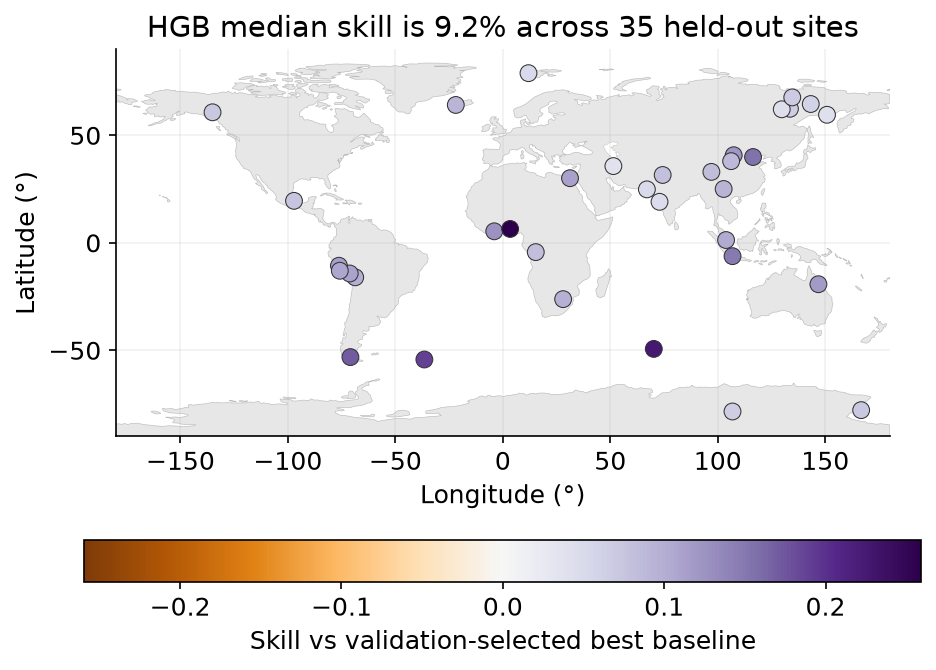

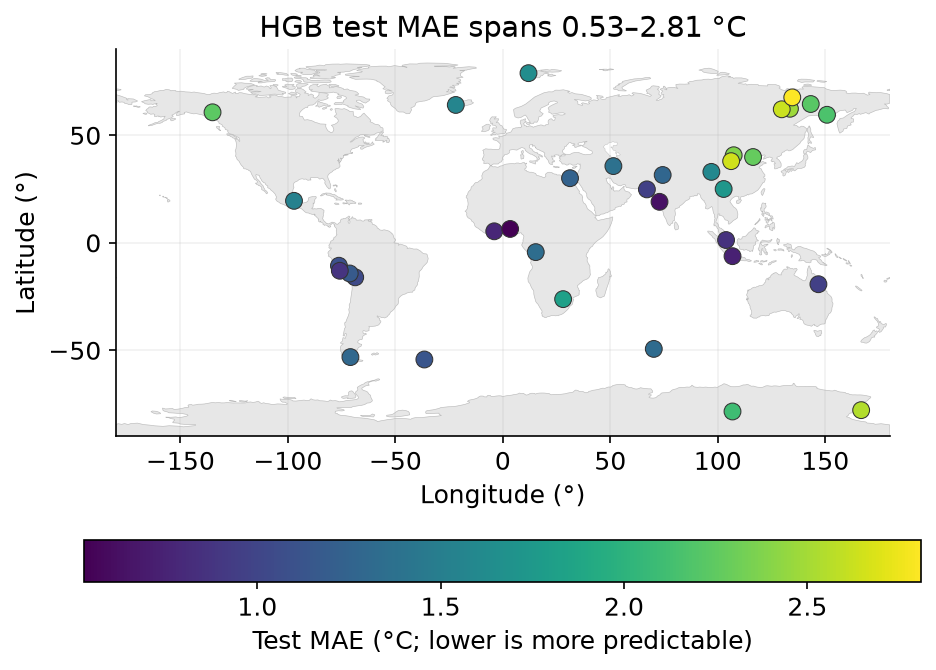

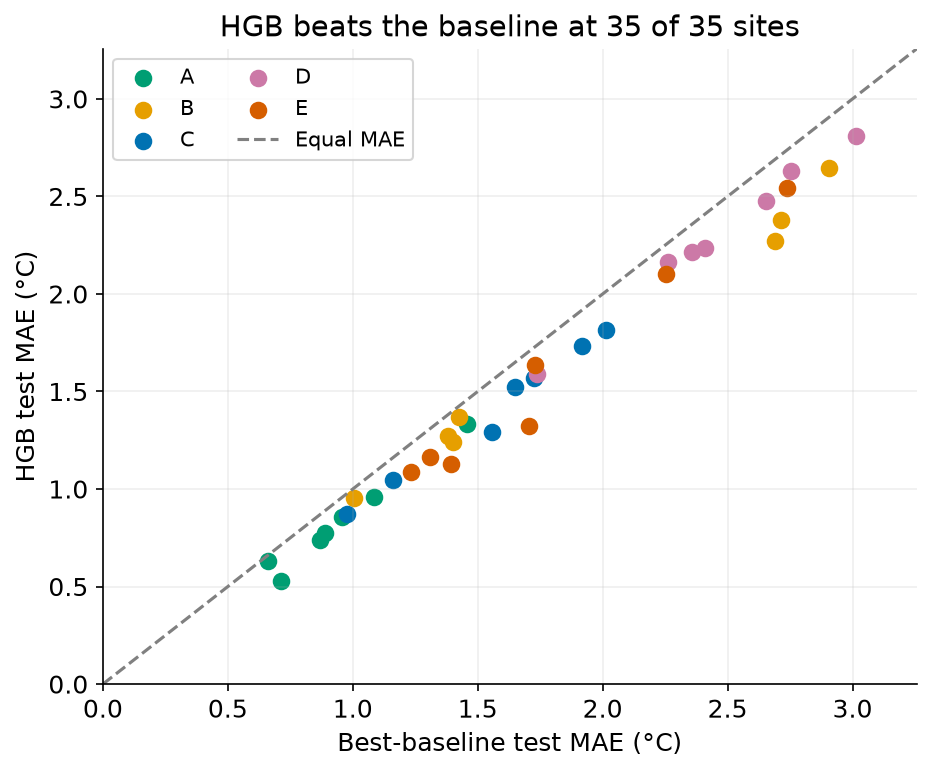

,model,reference,median_skill,q25_skill,q75_skill,n_sites,n_significant,fraction_significant
0,hgb,best_baseline,0.091587,0.066994,0.116583,35,34,0.971429
1,hgb,climatology,0.324209,0.274448,0.423844,35,35,1.000000
2,hgb,persistence,0.094494,0.066994,0.136347,35,34,0.971429
3,hgb_pooled,best_baseline,0.093852,0.071614,0.109962,35,33,0.942857
4,hgb_pooled,climatology,0.330021,0.263859,0.423419,35,34,0.971429
5,hgb_pooled,persistence,0.095652,0.078032,0.139391,35,34,0.971429
6,linear,best_baseline,0.090116,0.067500,0.117147,35,32,0.914286
7,linear,climatology,0.315753,0.267319,0.419265,35,35,1.000000
8,linear,persistence,0.092629,0.067500,0.122510,35,32,0.914286


In [2]:
def figure(name):
    display(Image(filename=str(FIGURES / name), width=900))
figure('skill_map.png')
figure('mae_map.png')
figure('baseline_vs_model.png')
display(pd.DataFrame(findings['skill_summary']))

## Climate groups and training-period drivers

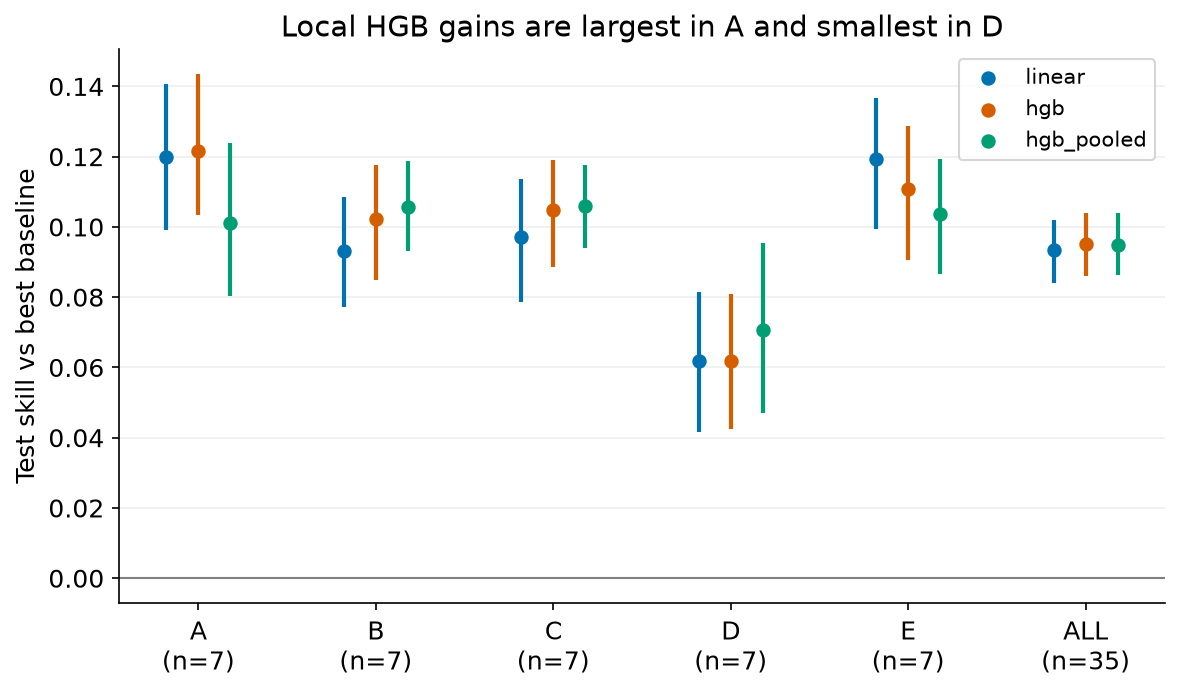

,best,worst
hgb,"{'koppen_group': 'A', 'split': 'test', 'model'...","{'koppen_group': 'D', 'split': 'test', 'model'..."
hgb_pooled,"{'koppen_group': 'C', 'split': 'test', 'model'...","{'koppen_group': 'D', 'split': 'test', 'model'..."
linear,"{'koppen_group': 'A', 'split': 'test', 'model'...","{'koppen_group': 'D', 'split': 'test', 'model'..."


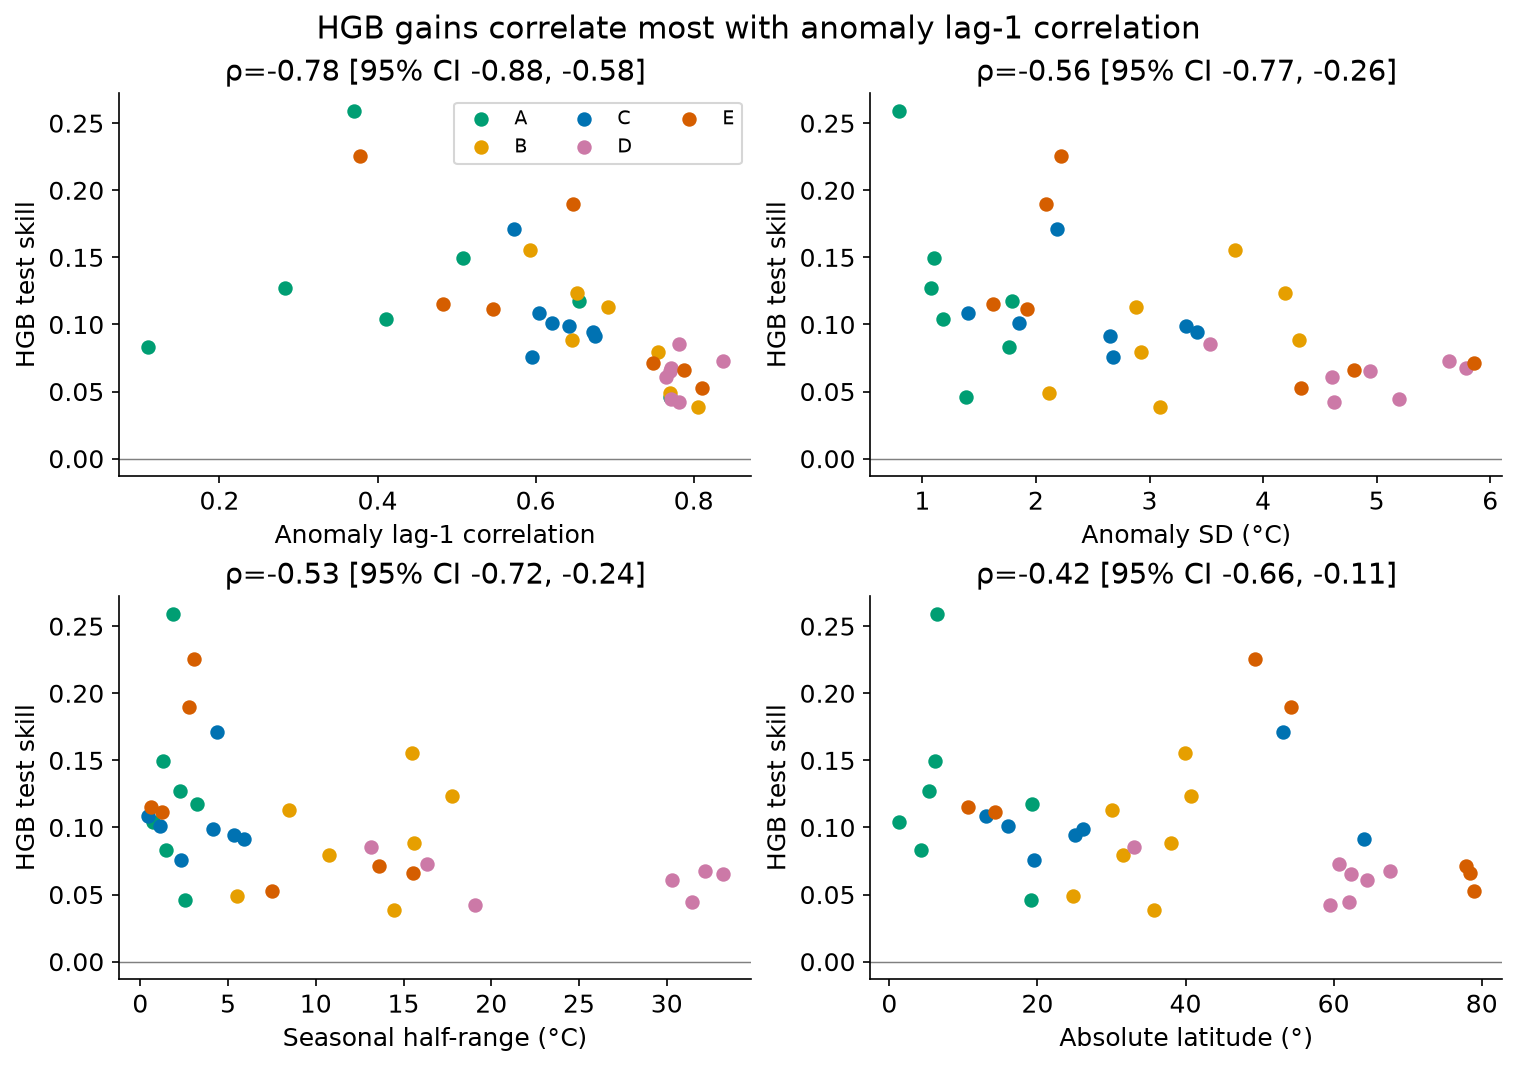

,model,reference,outcome,driver,rho,ci_low,ci_high,n_sites,n_valid_reps,absolute_rho
0,hgb,best_baseline,skill,anomaly_acf1,-0.776471,-0.875866,-0.577791,35,1000,0.776471
1,hgb_pooled,best_baseline,skill,anomaly_acf1,-0.695798,-0.869198,-0.367983,35,1000,0.695798
2,linear,best_baseline,skill,anomaly_acf1,-0.682073,-0.830275,-0.448183,35,1000,0.682073
3,hgb,best_baseline,skill,anomaly_sd,-0.556022,-0.766884,-0.264237,35,1000,0.556022
4,hgb,best_baseline,skill,seasonal_amplitude,-0.527731,-0.718518,-0.243481,35,1000,0.527731
5,linear,best_baseline,skill,anomaly_sd,-0.477591,-0.717818,-0.165099,35,1000,0.477591
6,linear,best_baseline,skill,seasonal_amplitude,-0.454062,-0.668927,-0.165473,35,1000,0.454062
7,hgb,best_baseline,skill,abs_lat,-0.422689,-0.662607,-0.109384,35,1000,0.422689
8,hgb_pooled,best_baseline,skill,anomaly_sd,-0.372549,-0.648570,-0.042156,35,1000,0.372549
9,hgb_pooled,best_baseline,skill,seasonal_amplitude,-0.310644,-0.557136,0.004246,35,1000,0.310644


In [3]:
figure('skill_by_group.png')
display(pd.DataFrame(findings['group_extremes']).T)
figure('skill_vs_driver.png')
display(pd.DataFrame(findings['top_driver_correlations']))

Correlations are descriptive associations across sampled sites. Bootstrap intervals do
not adjust for testing several drivers. Weather variability, latitude and climate class
are related, so these associations should not be read as independent causal effects.

## Calendar months, local seasons and losing sites

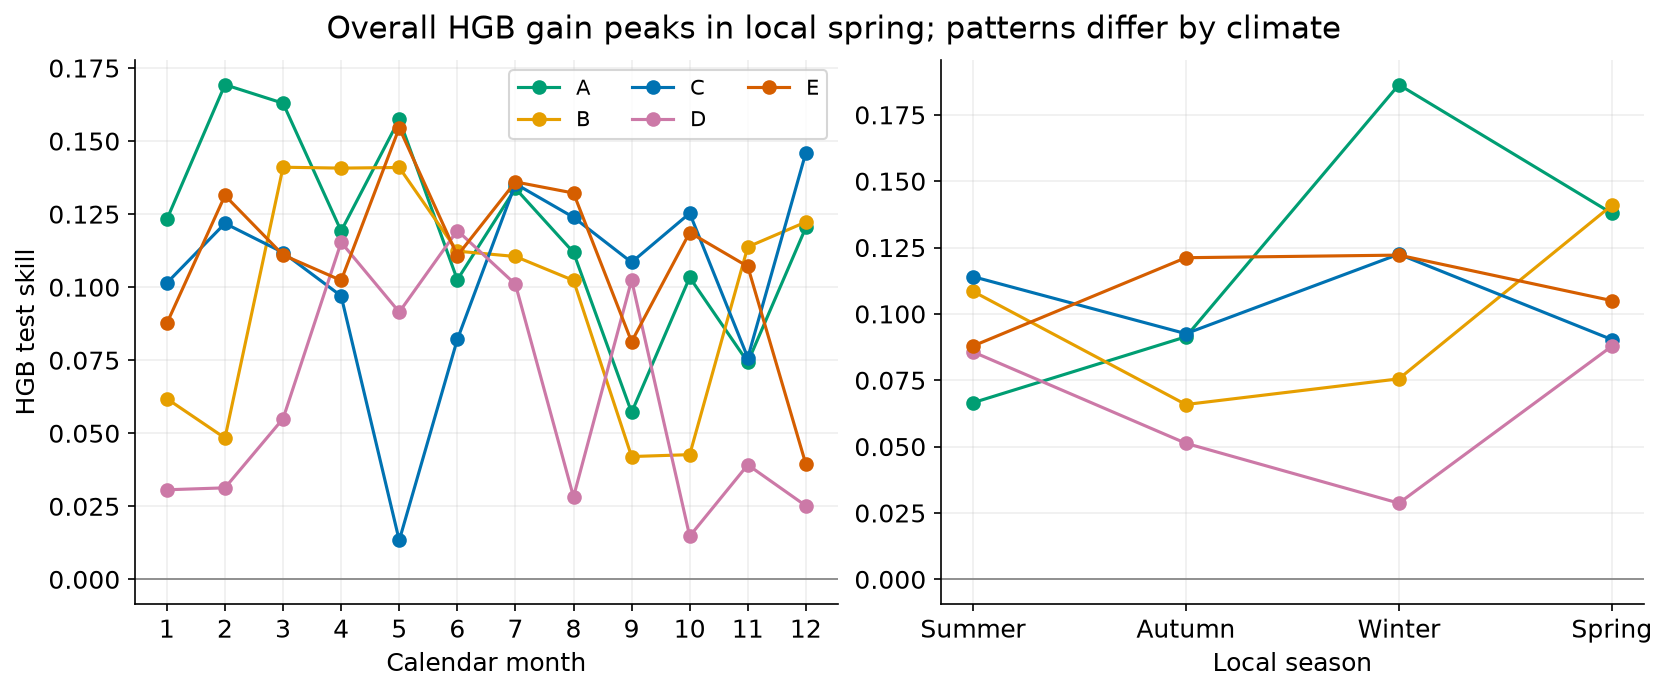

,period_type,period,koppen_group,model,reference,mae_model,mae_ref,skill,n_sites,n_pairs
1091,local_season,autumn,A,hgb,best_baseline,0.799482,0.879873,0.091367,7,1280
1106,local_season,autumn,B,hgb,best_baseline,1.612234,1.725903,0.065860,7,1274
1121,local_season,autumn,C,hgb,best_baseline,1.310901,1.444599,0.092551,7,1282
1136,local_season,autumn,D,hgb,best_baseline,2.079039,2.191366,0.051259,7,1274
1151,local_season,autumn,E,hgb,best_baseline,1.592613,1.812192,0.121168,7,1286
1166,local_season,autumn,ALL,hgb,best_baseline,1.478854,1.610786,0.081906,35,6396
1181,local_season,spring,A,hgb,best_baseline,0.864967,1.003310,0.137887,7,1282
1196,local_season,spring,B,hgb,best_baseline,2.137054,2.487578,0.140909,7,1288
1211,local_season,spring,C,hgb,best_baseline,1.555823,1.710296,0.090319,7,1280
1226,local_season,spring,D,hgb,best_baseline,1.942308,2.129348,0.087839,7,1288


No negative point-skill sites in this run.

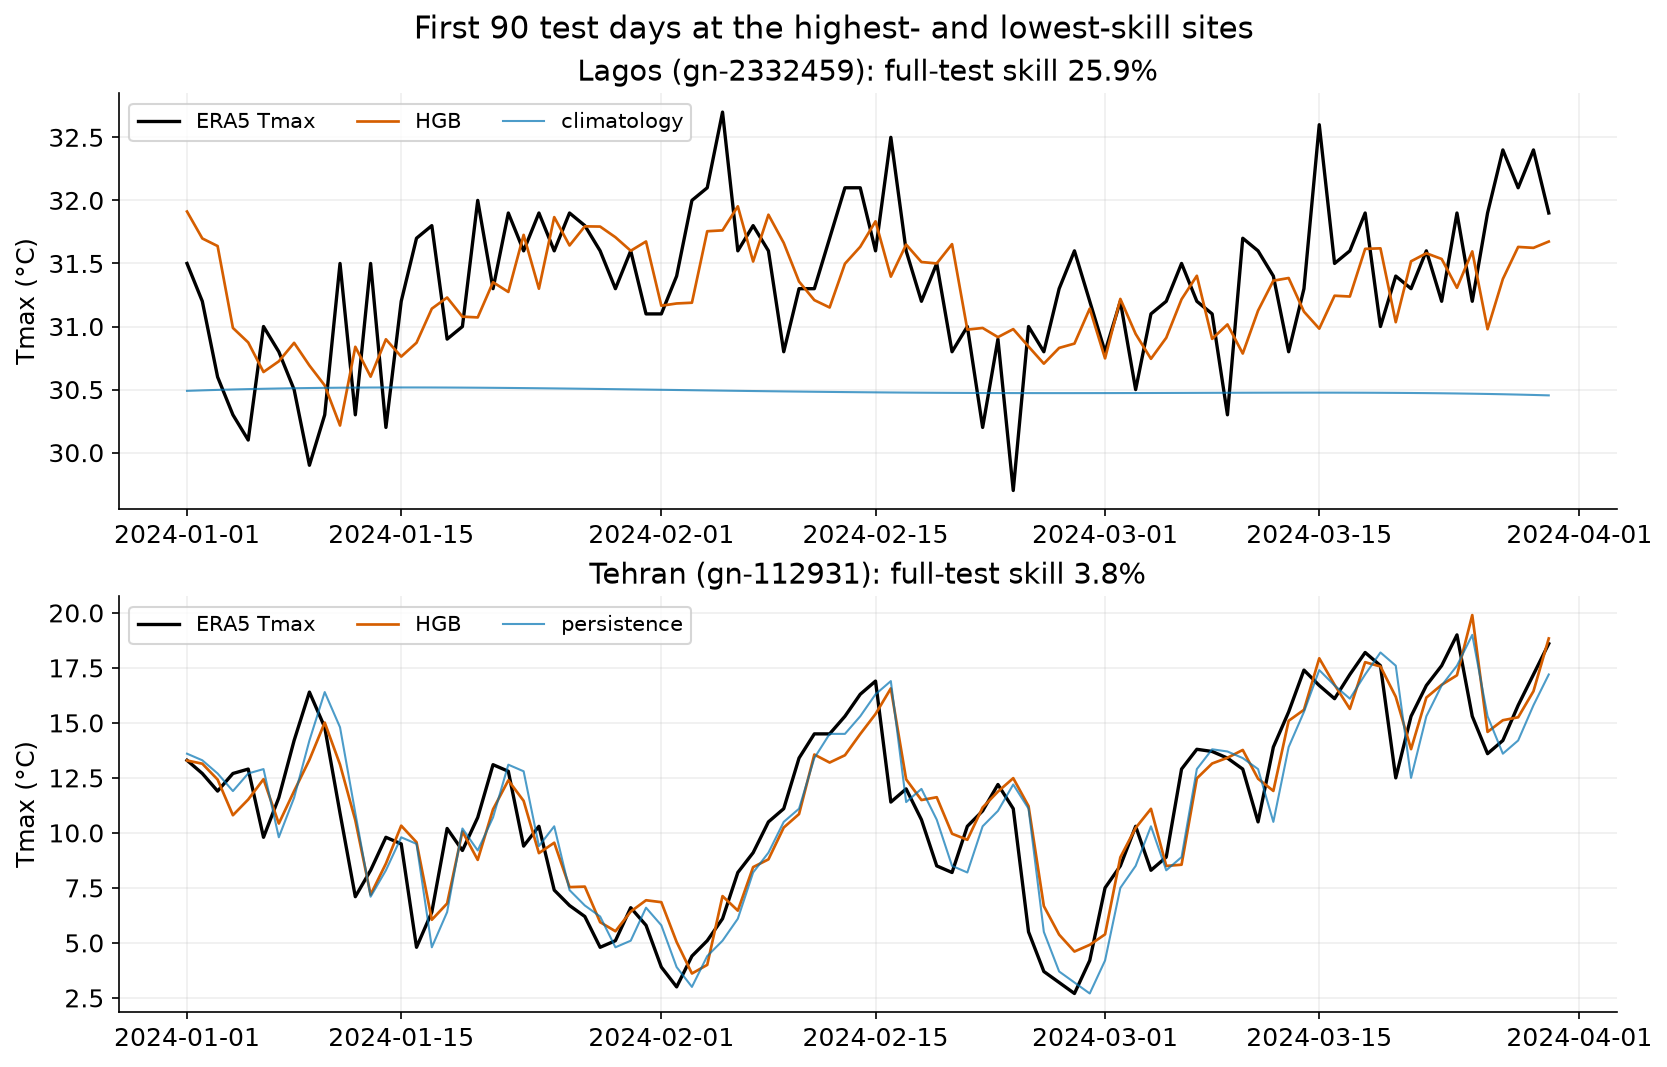

In [4]:
figure('seasonal.png')
seasonal = pd.read_csv(PROCESSED / 'seasonal_group.csv')
display(seasonal.query("period_type == 'local_season' and model == 'hgb' "
                       "and reference == 'best_baseline' and n_sites > 0"))
losing = pd.DataFrame(findings['losing_sites'])
display(losing if len(losing) else Markdown('No negative point-skill sites in this run.'))
figure('example_city.png')

Local seasons reverse north/south meteorological seasons; the equator uses the northern
convention. Tropical wet/dry seasons need a different treatment. Losing-site explanations
are driver-based hypotheses, not established causes. Example cities are selected after
evaluation as illustrations of extremes; their snippets are not a new evaluation set.

## Local versus pooled, and weather-feature ablation

mean_mae_local                     1.569240
mean_mae_pooled                    1.569581
mean_delta_pooled_minus_local      0.000341
median_delta_pooled_minus_local   -0.000262
fraction_pooled_better             0.514286
dtype: float64

,model,mean,median
0,hgb,-0.049478,-0.042109
1,hgb_pooled,-0.032754,-0.018090
2,linear,-0.038244,-0.027852


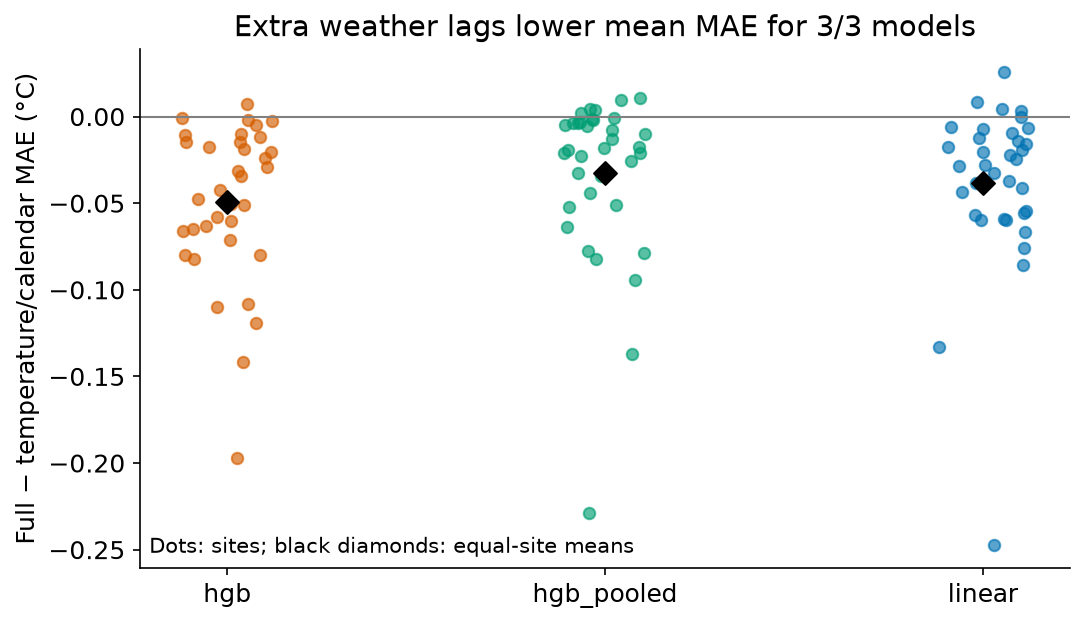

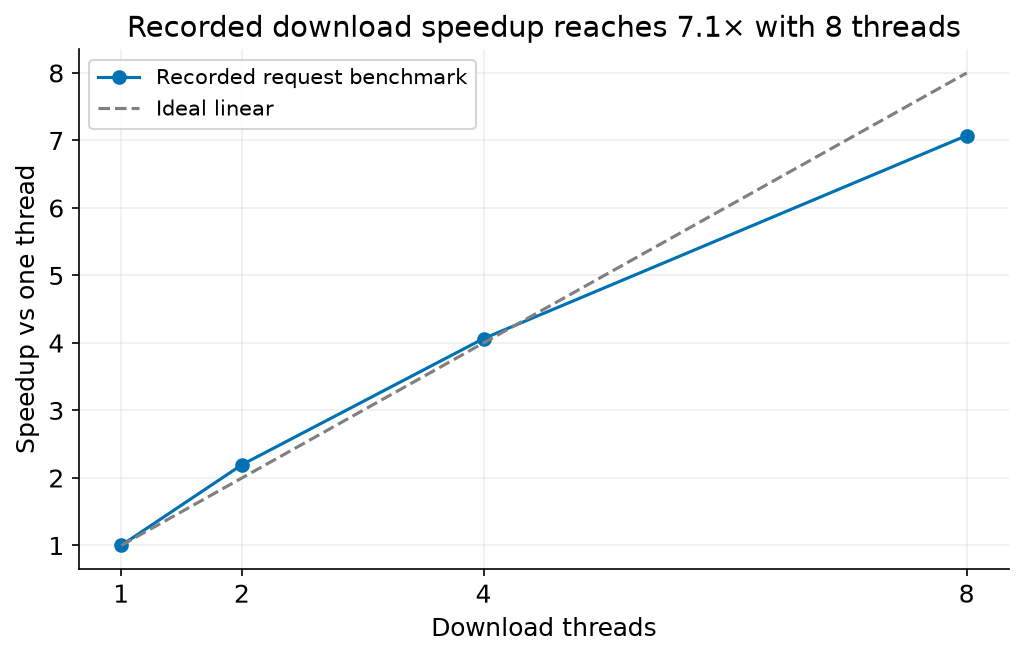

In [5]:
display(pd.Series(findings['pooled_vs_local']))
display(pd.DataFrame(findings['ablation_deltas']))
figure('ablation.png')
figure('concurrency_speedup.png')

## Computed conclusion

In [6]:
lines = [f"This held-out run covers {findings['n_sites']} complete sites."]
for row in findings['skill_summary']:
    if row['reference'] == 'best_baseline':
        lines.append(
            f"{row['model']}: median skill {row['median_skill']:.1%} "
            f"(IQR {row['q25_skill']:.1%}–{row['q75_skill']:.1%}); "
            f"{row['n_significant']}/{row['n_sites']} sites have a 95% interval above zero."
        )
pooled = findings['pooled_vs_local']
if pooled:
    lines.append(f"Pooled minus local HGB mean MAE is "
                 f"{pooled['mean_delta_pooled_minus_local']:+.3f} °C; "
                 f"pooling improves {pooled['fraction_pooled_better']:.1%} of sites.")
lines.extend(findings['caveats'])
display(Markdown(chr(10).join(lines)))

This held-out run covers 35 complete sites.
hgb: median skill 9.2% (IQR 6.7%–11.7%); 34/35 sites have a 95% interval above zero.
hgb_pooled: median skill 9.4% (IQR 7.2%–11.0%); 33/35 sites have a 95% interval above zero.
linear: median skill 9.0% (IQR 6.8%–11.7%); 32/35 sites have a 95% interval above zero.
Pooled minus local HGB mean MAE is +0.000 °C; pooling improves 51.4% of sites.
Preliminary subset; climate-group coverage may be unbalanced.
Intervals are conditional on fitted models; no model-selection uncertainty.
Exploratory driver correlations have no multiple-comparison adjustment.
Loss explanations are hypotheses, not causal conclusions.
Local seasons are meteorological; tropical wet/dry seasons are not represented.